In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = DATA_DIR / "Images"
RESULT_DIR = PROJECT_DIR / "results"

print("Error analysis setup complete!")

Error analysis setup complete!


In [3]:
import pandas as pd
import numpy as np

CSV_PATH = DATA_DIR / "FETAL_PLANES_DB_data.csv"

df = pd.read_csv(CSV_PATH, sep=";")
df.columns = df.columns.str.strip()

test_df = df[df["Train"] == 0].reset_index(drop=True).copy()

# Load saved predictions from Notebook 4
prediction_df = pd.read_csv(
    RESULT_DIR / "baseline_test_predictions.csv"
)

class_names = sorted(df["Plane"].unique())

print("Test images:", len(test_df))
print("Saved predictions:", len(prediction_df))
print("Classes:", class_names)

Test images: 5271
Saved predictions: 5271
Classes: ['Fetal abdomen', 'Fetal brain', 'Fetal femur', 'Fetal thorax', 'Maternal cervix', 'Other']


In [7]:
# Recreate error dataframe from test data and saved predictions

error_df = test_df.reset_index(drop=True).copy()

error_df["Actual"] = prediction_df["Actual"].values
error_df["Predicted"] = prediction_df["Predicted"].values

error_df = error_df[
    error_df["Actual"] != error_df["Predicted"]
].copy()

error_df["Image_Path"] = error_df["Image_name"].apply(
    lambda x: IMAGE_DIR / f"{x}.png"
)

print("Columns:", error_df.columns.tolist())
print("Total errors:", len(error_df))
print("\nErrors by actual class:")
print(error_df["Actual"].value_counts())

Columns: ['Image_name', 'Patient_num', 'Plane', 'Brain_plane', 'Operator', 'US_Machine', 'Train', 'Actual', 'Predicted', 'Image_Path']
Total errors: 331

Errors by actual class:
Actual
Other              215
Fetal femur         49
Fetal abdomen       34
Fetal thorax        25
Fetal brain          6
Maternal cervix      2
Name: count, dtype: int64


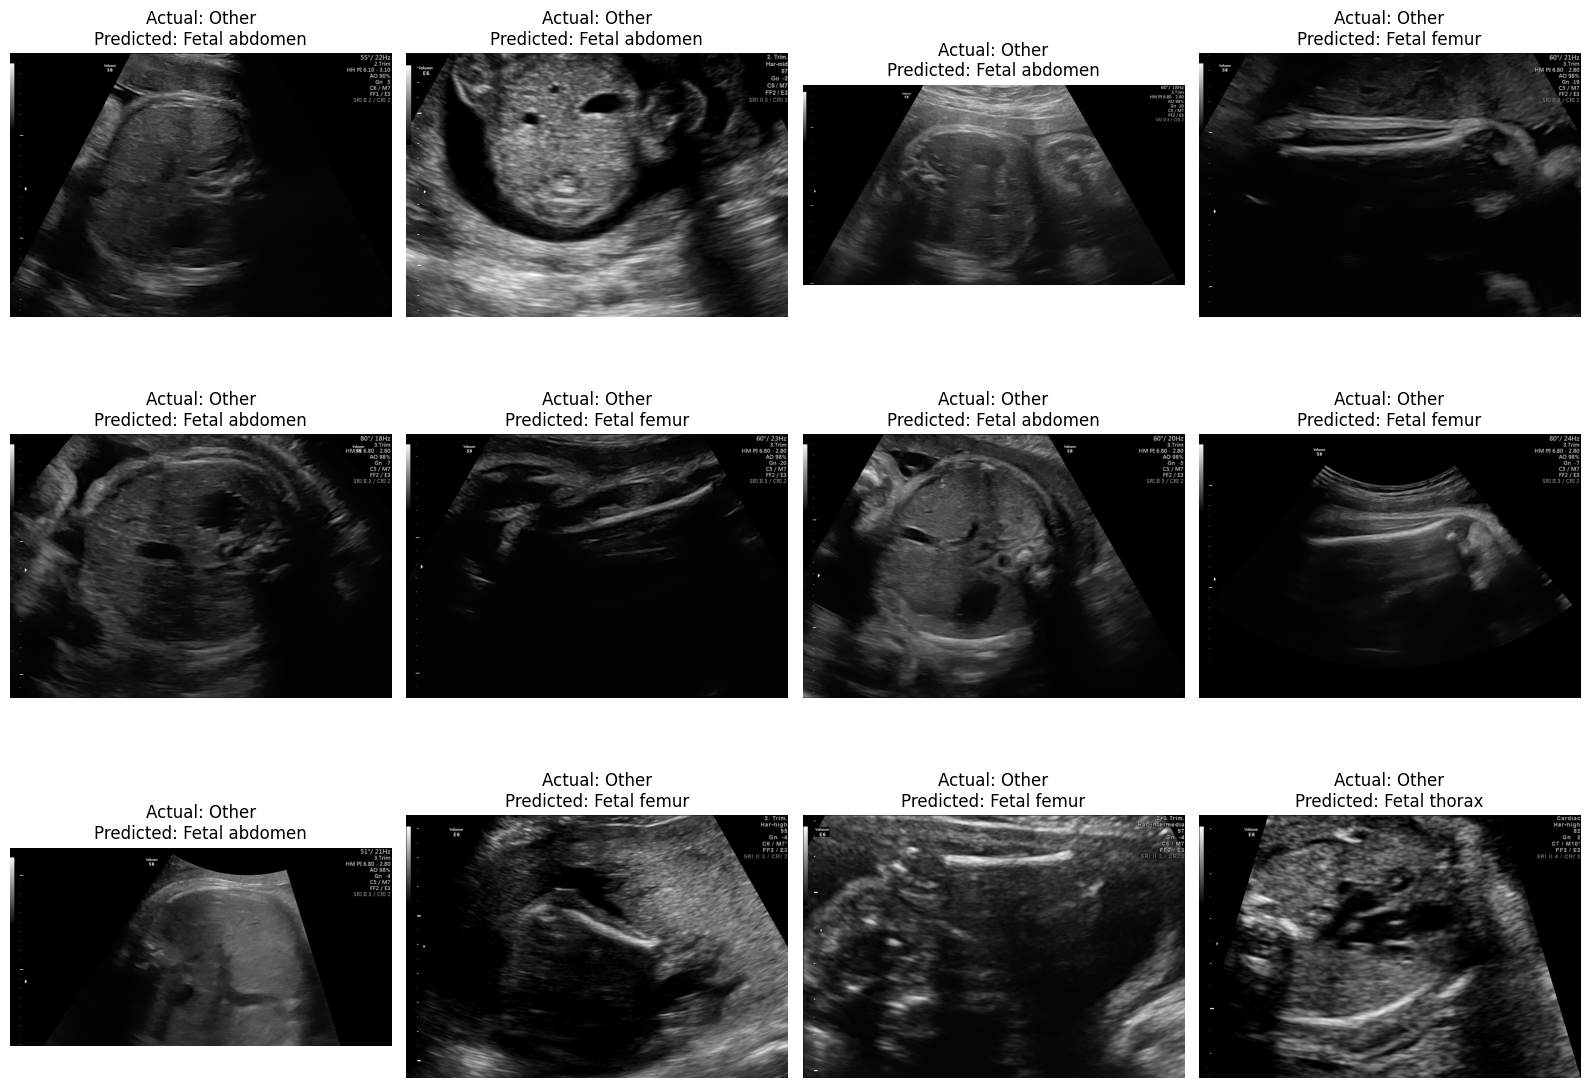

In [8]:
sample_errors = error_df[
    error_df["Actual"] == "Other"
].head(12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, (_, row) in enumerate(sample_errors.iterrows()):

    image = Image.open(row["Image_Path"]).convert("RGB")

    axes[i].imshow(image)
    axes[i].set_title(
        f"Actual: {row['Actual']}\nPredicted: {row['Predicted']}"
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Actual Other misclassification breakdown:

Predicted
Fetal abdomen      36
Fetal brain        12
Fetal femur        74
Fetal thorax       90
Maternal cervix     3
Other               0
Name: count, dtype: int64


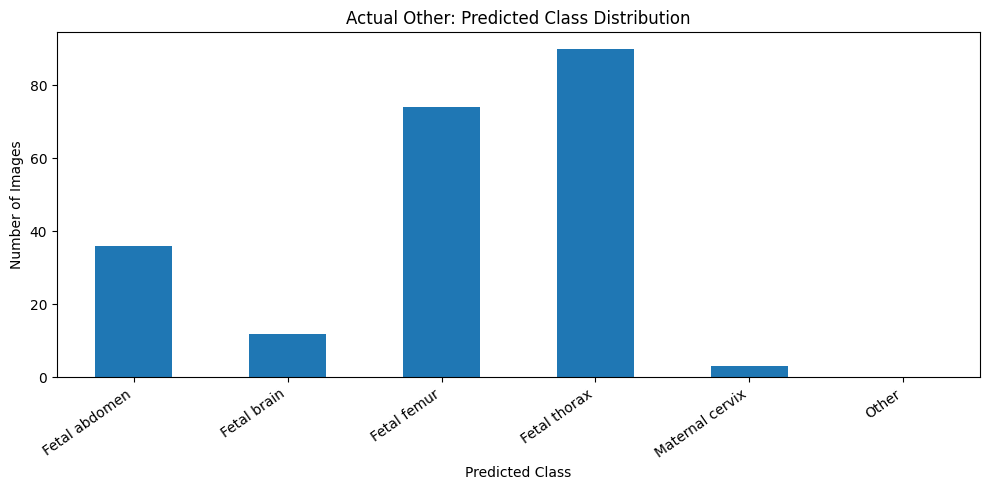

In [9]:
other_errors = error_df[
    error_df["Actual"] == "Other"
]

other_error_counts = (
    other_errors["Predicted"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

print("Actual Other misclassification breakdown:\n")
print(other_error_counts)

plt.figure(figsize=(10, 5))

other_error_counts.plot(
    kind="bar",
    title="Actual Other: Predicted Class Distribution"
)

plt.xlabel("Predicted Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

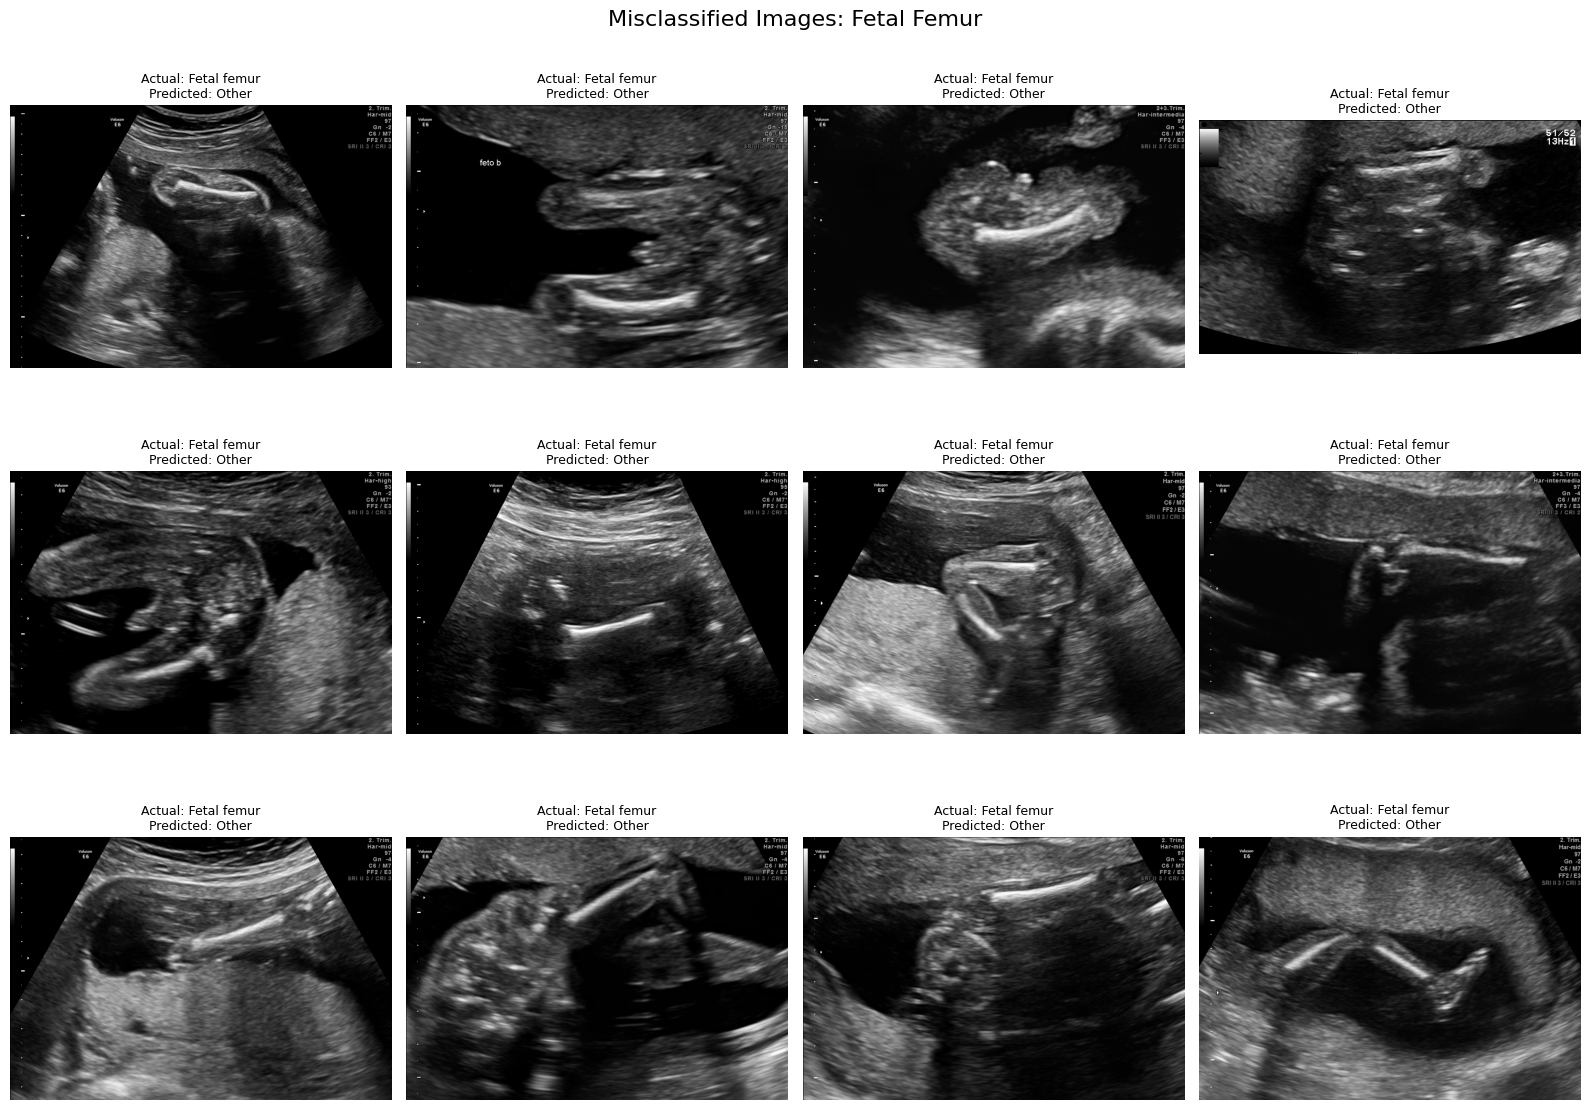

In [10]:
femur_errors = error_df[
    error_df["Actual"] == "Fetal femur"
].head(12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, (_, row) in enumerate(femur_errors.iterrows()):

    image = Image.open(row["Image_Path"]).convert("RGB")

    axes[i].imshow(image)
    axes[i].set_title(
        f"Actual: {row['Actual']}\nPredicted: {row['Predicted']}",
        fontsize=9
    )
    axes[i].axis("off")

plt.suptitle("Misclassified Images: Fetal Femur", fontsize=16)
plt.tight_layout()
plt.show()